# Data Exploration

In [1]:
import os
import numpy as np
import pandas as pd
from sqlalchemy import create_engine
from dotenv import load_dotenv
%matplotlib inline
from matplotlib import pyplot as plt

### Connecting to PostgreSQL database

In [2]:
load_dotenv()

host = os.getenv('PG_HOST')
username = os.getenv('PG_USER')
password = os.getenv('PG_PASSWORD')
port = os.getenv('PG_PORT')
database = os.getenv('PG_DB')

engine = create_engine(f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}")


#### 1. What data exists, how big is it, and what are the different columns?
- Here we try to understand how many rows and columns does each of the postgres database tables hold.
- Note that the number of rows in each result would keep changing everyday as data keeps getting fetched and fed into our postgres database.
- Row counts tell us which tables hold one row per object and which hold one row per object per snapshot.

In [3]:
db_tables = ['source_log', 'object_dimension', 'object_alias', 'orbit',
          'sentry_risk', 'risk_removal', 'close_approach', 'risk_change']

# The above table names were taken from the PostgreSQL database

df = {}

for table in db_tables:
    df[table] = pd.read_sql(f"SELECT * FROM {table}", engine)
    print(f"{table}: {df[table].shape}")

source_log: (63, 7)
object_dimension: (43015, 12)
object_alias: (88254, 4)
orbit: (44511, 32)
sentry_risk: (53359, 17)
risk_removal: (3588, 5)
close_approach: (38995, 18)
risk_change: (225, 14)


In [4]:
# Re-naming for easier recollection

df_source = df['source_log']
df_object_dim = df['object_dimension']
df_object_alias = df['object_alias']
df_orbit = df['orbit']
df_sentry_risk = df['sentry_risk']
df_risk_removal = df['risk_removal']
df_close_approach = df['close_approach']
df_risk_change = df['risk_change']

In [5]:
# Displaying each column from each table

for table in db_tables:
    print(f"\n\nColumns in table {table}: \n\n", df[table].columns)



Columns in table source_log: 

 Index(['source_file', 'collection', 'fetched', 'params', 'api_version',
       'row_count', 'loaded_at'],
      dtype='str')


Columns in table object_dimension: 

 Index(['spkid', 'pdes', 'full_name', 'class', 'is_comet', 'h', 'h_sigma',
       'diameter', 'albedo', 'first_seen', 'last_seen', 'source_file'],
      dtype='str')


Columns in table object_alias: 

 Index(['alias_type', 'alias_value', 'spkid', 'source_file'], dtype='str')


Columns in table orbit: 

 Index(['spkid', 'orbit_id_num', 'epoch', 'epoch_ts', 'e', 'a', 'q', 'i', 'om',
       'w', 'ma', 'n', 'per', 'moid', 'pha', 'rms', 'condition_code',
       'n_obs_used', 'n_del_obs_used', 'n_dop_obs_used', 'data_arc',
       'last_obs', 'sigma_a', 'sigma_e', 'sigma_q', 'sigma_i', 'sigma_w',
       'sigma_tp', 'valid_from', 'valid_to', 'is_current', 'source_file'],
      dtype='str')


Columns in table sentry_risk: 

 Index(['des', 'source_file', 'spkid', 'sentry_id', 'h', 'diameter', 'v_inf',

In [6]:
for table in db_tables:
    print(f"\n\nHere are the first 5 rows of table {table}: \n\n", df[table].head())



Here are the first 5 rows of table source_log: 

              source_file collection                          fetched  \
0  20261009T200114Z.json        cad 2026-10-09 20:01:14.820000+00:00   
1  20261010T085134Z.json        cad 2026-10-10 08:51:34.141000+00:00   
2  20261010T085915Z.json        cad 2026-10-10 08:59:15.695000+00:00   
3  20261010T085253Z.json       sbdb 2026-10-10 08:52:53.528000+00:00   
4  20261009T200111Z.json   sentry_r 2026-10-09 20:01:11.340000+00:00   

                                              params api_version  row_count  \
0                                                 {}         1.5         45   
1                                                 {}         1.5         45   
2                                                 {}         1.5         45   
3  {'fields': 'spkid,neo,pha,pdes,full_name,class...         1.0      42917   
4                                   {'removed': '1'}         2.0       3580   

                         loaded_at  
0 2

- The row counts separate two kinds of tables: those holding one row per object, and those holding one row per object per snapshot. The second kind grow with every load, so any statistic computed on them must first be filtered to a single fetch - otherwise each object is weighted by how often it was captured.
- The snapshot registry's row count is itself the number of fetches performed.
- Combined with the physical and observational meaning of each parameter, we can understand what our data contains.

#### 2. What are the data types for each column in every table? 
- pandas infers types when reading, and a numeric column that arrives as 'object' is silently skipped by describe() and dropped by corr() - no error is raised, but the column simply disappears from the result.
- So this is checked before any statistic is computed.

In [7]:
for table in db_tables:
    print(f"The data types for each column in {table} are: \n\n", df[table].dtypes)

The data types for each column in source_log are: 

 source_file                    str
collection                     str
fetched        datetime64[us, UTC]
params                      object
api_version                    str
row_count                    int64
loaded_at      datetime64[us, UTC]
dtype: object
The data types for each column in object_dimension are: 

 spkid                        int64
pdes                           str
full_name                      str
class                          str
is_comet                      bool
h                          float64
h_sigma                    float64
diameter                   float64
albedo                     float64
first_seen     datetime64[us, UTC]
last_seen      datetime64[us, UTC]
source_file                    str
dtype: object
The data types for each column in object_alias are: 

 alias_type       str
alias_value      str
spkid          int64
source_file      str
dtype: object
The data types for each column in orbit ar

- From above, we can see that there exist different data-type columns, including 'object' type.
- Notice that these 'object' types are source_log.params (a dict, so it cannot be compared or de-duplicated), orbit.pha (a nullable boolean, which numpy's bool dtype cannot represent), and orbit.last_obs and close_approach.approach_date — Postgres DATE columns that pandas does not auto-parse. The last one has to be cast before any time grouping.

#### 3. What fraction of each column from each table is null?
- Important to characterize this as this would decide which columns can be features at all in the downstream ML modelling, and which API responses must document a nullable field. 

In [8]:
for table in db_tables:
    print(f"\n\nThe total null values for each colum in {table} are: \n\n")
    print((df[table].isnull().sum() / len(df[table]) * 100).round(2))



The total null values for each colum in source_log are: 


source_file    0.0
collection     0.0
fetched        0.0
params         0.0
api_version    0.0
row_count      0.0
loaded_at      0.0
dtype: float64


The total null values for each colum in object_dimension are: 


spkid           0.00
pdes            0.00
full_name       0.00
class           0.00
is_comet        0.00
h               0.51
h_sigma        42.84
diameter       97.06
albedo         97.19
first_seen      0.00
last_seen       0.00
source_file     0.00
dtype: float64


The total null values for each colum in object_alias are: 


alias_type     0.0
alias_value    0.0
spkid          0.0
source_file    0.0
dtype: float64


The total null values for each colum in orbit are: 


spkid              0.00
orbit_id_num       0.00
epoch              0.00
epoch_ts           0.00
e                  0.00
a                  0.00
q                  0.00
i                  0.00
om                 0.00
w                  0.00
ma     

des            0.00
source_file    0.00
spkid          0.04
sentry_id      0.00
h              0.00
diameter       0.00
v_inf          0.19
ip             0.00
ps_cum         0.00
ps_max         0.00
ts_max         0.09
n_imp          0.00
last_obs_jd    0.00
last_obs_ts    0.00
range_start    0.00
range_end      0.00
fetched        0.00
dtype: float64


The total null values for each colum in risk_removal are: 


des              0.00
spkid           21.74
removed          0.00
first_listed     0.00
source_file      0.00
dtype: float64


The total null values for each colum in close_approach are: 


des              0.00
approach_date    0.00
orbit_id_num     0.00
spkid            0.00
jd               0.00
jd_raw           0.00
approach_ts      0.00
cd_raw           0.00
dist             0.00
dist_min         0.00
dist_max         0.00
dist_raw         0.00
dist_min_raw     0.00
dist_max_raw     0.00
v_rel            0.00
v_inf            0.06
t_sigma_f        0.00
source_file      0

- The columns that are almost entirely empty fall into two groups with different causes.
- The physical ones: diameter, albedo and the two radar observation counts are published by JPL only where a radar or thermal measurement exists, which is rare. The radar counts and the measured diameters are populated for nearly the same objects, because a radar campaign yields both at once.
- The pipeline one: mean anomaly, mean motion and period are empty for almost every row because the orbit table gains a new row only when the orbit solution changes. Rows created by the first SBDB fetch keep that fetch's field list permanently, and these three were requested later. 
- In the change table, the 'after' columns are null for precisely the rows where the object left Sentry: an object no longer listed has no after-value.

- So far we saw the inventory that exists in our database. Now we need to go further to check the shape of each column in each table. This would give an idea of what one row means in each table.

#### 4. What does one row mean in each table?
- Postgres primary keys make duplicates impossible, so this is not testing the database. It confirms the loader did not drop rows to satisfy a key. Testing across all columns answers two different questions: whether the key holds, and whether any rows are redundant copies.
- This is needed for our downstream ML task. This is because our ML label is built by taking differences between consecutive snapshots — so irregular spacing changes what the label means, row by row.

In [9]:
PKS = {
    "source_log":       ["source_file"],
    "object_dimension": ["spkid"],
    "object_alias":     ["alias_type", "alias_value"],
    "orbit":            ["spkid", "orbit_id_num"],
    "sentry_risk":      ["des", "source_file"],
    "risk_removal":     ["des"],
    "close_approach":   ["des", "approach_date", "orbit_id_num"],
    "risk_change":      ["des", "fetched"],
} # These list the primary keys of each table in postgres database

fixed = {"source_log": ["params"]}

print(f"{'table':18s} {'primary key':45s} {'at grain':>9s} {'identical':>10s}\n")

for table in db_tables:
    pk = PKS[table]
    at_grain = df[table].duplicated(subset=pk).sum()

    cols = [c for c in df[table].columns if c not in fixed.get(table, [])]
    identical = df[table][cols].duplicated().sum()

    print(f"{table:18s} {str(pk):45s} {at_grain:9d} {identical:10d}")



table              primary key                                    at grain  identical

source_log         ['source_file']                                       0          0
object_dimension   ['spkid']                                             0          0


object_alias       ['alias_type', 'alias_value']                         0          0
orbit              ['spkid', 'orbit_id_num']                             0          0
sentry_risk        ['des', 'source_file']                                0          0
risk_removal       ['des']                                               0          0
close_approach     ['des', 'approach_date', 'orbit_id_num']              0          0
risk_change        ['des', 'fetched']                                    0          0


- This shows that our primary key fixture is in place and functioning as it should. Moreover, we also notice that the values from other columns are not duplicated either.

- Next we need to check what are the gaps between consecutive fetches, per collection?

In [10]:
# This says how regular are the fetches for each collection

gaps = df_source.sort_values("fetched").copy()
gaps["gap_h"] = gaps.groupby("collection")["fetched"].diff().dt.total_seconds() / 3600

print("\nHours between consecutive fetches: \n")
print(gaps.groupby("collection")["gap_h"].describe().round(2))

print("\nGaps over 30 hours (missed runs): \n")
print(gaps[gaps["gap_h"] > 30][["collection", "source_file", "gap_h"]].to_string(index=False))

print("\nGaps under 1 hour: \n")
print(gaps[gaps["gap_h"] < 1][["collection", "source_file", "gap_h"]].to_string(index=False))



Hours between consecutive fetches: 

            count   mean    std   min    25%    50%    75%     max
collection                                                        
cad           7.0  54.22  65.38  0.13   6.87  20.74  86.94  171.03
sbdb          6.0  61.11  68.13  1.00   8.07  39.36  98.53  171.03
sentry_r     23.0  22.95  13.13  0.07  16.84  22.92  25.87   55.37
sentry_s     23.0  22.95  13.13  0.07  16.84  22.92  25.87   55.37

Gaps over 30 hours (missed runs): 

collection           source_file      gap_h
       cad 20261013T202720Z.json  61.830706
      sbdb 20261013T202734Z.json  57.982055
  sentry_s 20261016T140636Z.json  30.695248
  sentry_r 20261016T140640Z.json  30.695215
       cad 20261018T123026Z.json 112.051587
      sbdb 20261018T123033Z.json 112.049840
  sentry_s 20261022T135757Z.json  53.413112
  sentry_r 20261022T135801Z.json  53.413052
  sentry_s 20261025T153050Z.json  55.373523
  sentry_r 20261025T153054Z.json  55.373524
       cad 20261025T153159Z.json 171.02

- Lets check what exactly it is meant by 'current state'. That is, which filter defines the 'present', for each table that has history?

In [11]:
latest = df_sentry_risk[df_sentry_risk["fetched"] == df_sentry_risk["fetched"].max()].copy()
orbit = df_orbit[df_orbit["is_current"]].copy()

print(f"Current sentry snapshot: {len(latest):,} objects at {latest['fetched'].iloc[0]}")
print(f"Current orbit solutions: {len(orbit):,}")

Current sentry snapshot: 2,227 objects at 2026-10-31 19:48:22.402000+00:00
Current orbit solutions: 43,015


- Here, two different mechanisms define 'now': the risk table is filtered by its newest fetch timestamp, the orbit table carries an explicit flag. So using the flag where the timestamp is meant would attach a present-day orbit to a past risk assessment.

- Now that we have checked data integrity and data quality, now it is time to dig in and start checking different variables.

#### 5. How are objects distributed across orbit classes?
- There are 8 object classes. Lets check what their counts are.
- The class is a candidate model feature and the simplest way to describe what the catalogue contains. 

In [12]:
df_object_dim.groupby('is_comet')['class'].value_counts()

is_comet  class
False     APO      24345
          AMO      14934
          ATE       3488
          IEO         39
True      JFc        155
          HTC         37
          JFC         11
          ETc          6
Name: count, dtype: int64

- APO: Apollo Asteroids whose orbits cross Earth's orbit, with an orbital size larger than Earth's.
- AMO: Amor Asteroids that approach Earth's orbit but do not cross it under the standard classification.
- ATE: Aten Asteroids with smaller orbits than Earth's that can cross Earth's orbital path.
- IEO: Interior Earth Object (Atira)

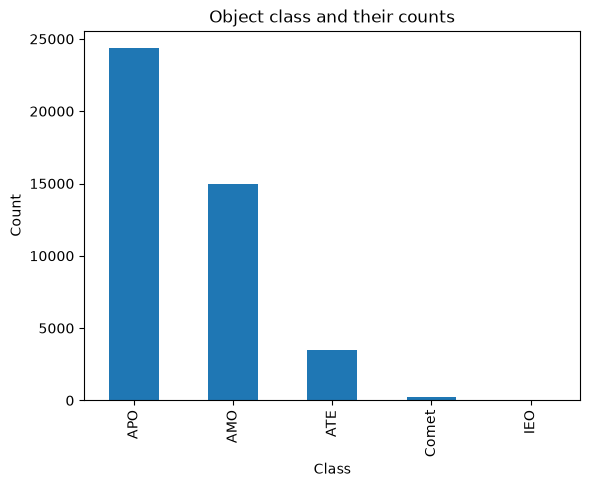

In [13]:
# Our goal is focussed on asteroids.
# We need to weed out the objects that were also observed, but were classified as comets.

comets = df_object_dim['class'].replace(['JFc', 'HTC', 'JFC', 'ETc'], 'Comet').value_counts()

comets.plot(kind='bar')
plt.xlabel('Class')
plt.ylabel('Count')
plt.title('Object class and their counts')
plt.show()

- This shows that the majority of objects that we need to care about are APO, AMO and ATE.

#### 6. Which classes are over-represented as Sentry?
- The 'object_dimension' contains all the objects, while the 'sentry_risk' carries those objects that are deemed as risky (considering their potential impact risks).
- We need to check if certain objects are more common in the sentry risk or in the general object population.
- This is because raw counts alone don’t tell us much; the ratios help us check whether an object's menbership in 'sentry_risk' makes sense based on the objects’ physical properties. If the ratios look unexpected, there may be an error in the class mapping or in how the datasets were joined.

In [14]:
od = df_object_dim
s = df["sentry_risk"]

on_sentry = set(s[s["fetched"] == s["fetched"].max()]["spkid"].dropna())
is_sentry = od["spkid"].isin(on_sentry)

enrich = pd.DataFrame({"all": od["class"].value_counts(),
                       "on_sentry": od.loc[is_sentry, "class"].value_counts(),
                        }).fillna(0).astype(int)

enrich["all_share"]    = enrich["all"] / enrich["all"].sum()
enrich["sentry_share"] = enrich["on_sentry"] / enrich["on_sentry"].sum()
enrich["enrichment"]   = enrich["sentry_share"] / enrich["all_share"]

enrich.sort_values("enrichment", ascending=False).round(2)

,all,on_sentry,all_share,sentry_share,enrichment
class,,,,,
ATE,3488,290,0.08,0.13,1.61
APO,24345,1907,0.57,0.86,1.52
AMO,14934,27,0.35,0.01,0.03
ETc,6,0,0.00,0.00,0.00
HTC,37,0,0.00,0.00,0.00
IEO,39,0,0.00,0.00,0.00
JFC,11,0,0.00,0.00,0.00
JFc,155,0,0.00,0.00,0.00


- **= 1**: The class is represented in sentry_risk at the same proportion as in the general object population.
- **< 1**: The class is under-represented in sentry_risk. 
- **> 1**: The class is over-represented in sentry_risk.

- This also shows and supports the physics behind. ATE and APO cross Earth's orbit and are enriched by ~1.5×. AMO have perihelion outside Earth's orbit and therefore cannot strike earth. 0.03 rather than exactly 0 only because a handful sit near the boundary. All 209 comets: exactly zero. IEOs, whose orbits lie entirely inside Earth's, also zero. So if an unexpected class dominates, we can easily suspect leakage.

#### 7. What scale do the risk measures need?
- What are the ranges of ip, ps_cum, ps_max? This would help determine whether ip and ps_cum rank risky objects similarly. That is, it helps check how the risk numbers are distributed so we can choose the correct type of chart.
- Table 'sentry_risk' has three risk-related columns: ip, ps_cum, and ps_max. Their values can have very different ranges. If we use the wrong chart scale, the data may look misleading or all the values may appear squeezed into one small area. For example, if some values are extremely small and others are much larger, a normal chart might not show the differences clearly.

current snapshot: 2,227 objects

ip (impact probability):
count    2.227e+03
mean     1.365e-04
std      2.308e-03
min      1.008e-10
25%      2.008e-07
50%      2.316e-06
75%      2.085e-05
max      1.026e-01
Name: ip, dtype: str

ps_cum / ps_max (Palermo scale - already log10, do not log it again):
        ps_cum   ps_max
count  2227.00  2227.00
mean     -6.90    -7.11
std       1.50     1.47
min     -12.13   -12.13
25%      -7.86    -8.05
50%      -6.81    -7.09
75%      -5.88    -6.12
max      -0.98    -0.98

ip spans 1.01e-10 to 1.03e-01
orders of magnitude: 9.0
mean / median ratio: 59.0

ps_cum >= ps_max for every row: True
highest ps_cum: -0.98  ->  10.5% of background impact risk


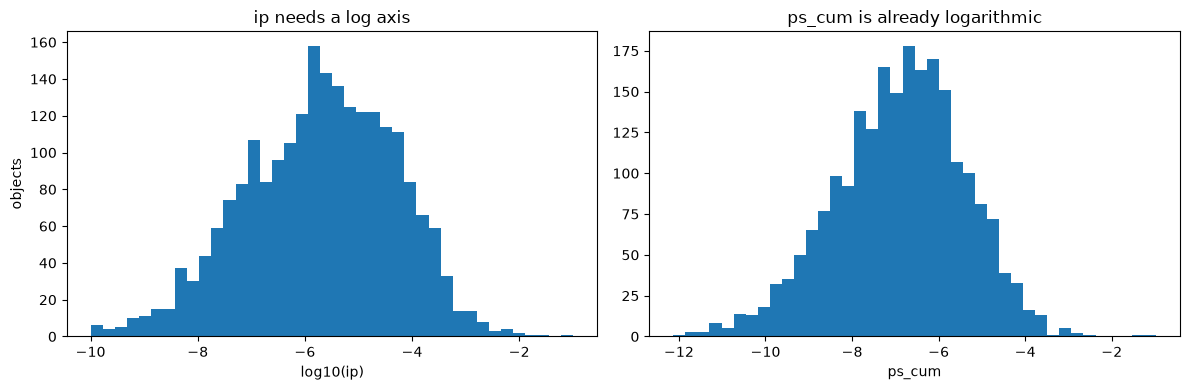

In [15]:
cur = df_sentry_risk[df_sentry_risk["fetched"] == df_sentry_risk["fetched"].max()].copy()
print(f"current snapshot: {len(cur):,} objects\n")

# scientific notation, because .round(6) prints ip's min as 0.000000
print("ip (impact probability):")
print(cur["ip"].describe().apply(lambda v: f"{v:.3e}"))

print("\nps_cum / ps_max (Palermo scale - already log10, do not log it again):")
print(cur[["ps_cum", "ps_max"]].describe().round(2))

print(f"\nip spans {cur['ip'].min():.2e} to {cur['ip'].max():.2e}")
print("orders of magnitude:", round(np.log10(cur["ip"].max() / cur["ip"].min()), 1))
print("mean / median ratio:", round(cur["ip"].mean() / cur["ip"].median(), 1))

# Integrity: cumulative hazard summed over all impact solutions can never sit
# below the single worst one. False here would mean two columns got swapped.
print("\nps_cum >= ps_max for every row:", (cur["ps_cum"] >= cur["ps_max"]).all())

worst = cur["ps_cum"].max()
print(f"highest ps_cum: {worst}  ->  {10 ** worst * 100:.1f}% of background impact risk")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(np.log10(cur["ip"]), bins=40)
ax[0].set_xlabel("log10(ip)"); ax[0].set_ylabel("objects")
ax[0].set_title("ip needs a log axis")
ax[1].hist(cur["ps_cum"], bins=40)
ax[1].set_xlabel("ps_cum"); ax[1].set_title("ps_cum is already logarithmic")
plt.tight_layout(); plt.show()

- Impact probability spans many orders of magnitude, with a mean far above its median. On a linear axis almost every object falls into the first bin, so any chart of it needs a logarithmic scale.
- The Palermo scale is already logarithmic by construction. It expresses risk relative to the background rate of random impacts. So taking its log again would be wrong. This asymmetry is why the two are plotted on different scales side by side.
- Every object in the catalogue sits below the background rate. That is, none presents a hazard above what the Earth experiences by chance anyway.

#### 8. State the target precisely and count it.
- That is, for each (des, fetched) row, did that object's risk change at the next snapshot?
- This is the ML target, and the failure mode is silent: keeping only the matched rows gives a plausible-looking frame with the classes inverted and no error.
- The unmatched rows are the negatives - objects whose risk did not change.

In [16]:
risk = df_sentry_risk.copy()
changes = df_risk_change.copy()

risk["fetched"] = pd.to_datetime(risk["fetched"], utc=True, errors="coerce")
changes["prev_fetched"] = pd.to_datetime(changes["prev_fetched"], utc=True, errors="coerce")

# Label: did ip or cumulative Palermo move at the next snapshot?
changes["risk_change"] = (changes["d_ip"].fillna(0).ne(0)
                          | changes["d_ps_cum"].fillna(0).ne(0)).astype("int8")

print("Duplicate risk keys: ", risk.duplicated(["des", "fetched"]).sum())
print("Duplicate label keys:", changes.duplicated(["des", "prev_fetched"]).sum())

labelled = risk.merge(changes[["des", "prev_fetched", "risk_change"]],
                      left_on=["des", "fetched"],
                      right_on=["des", "prev_fetched"],
                      how="left", indicator=True, validate="one_to_one")

matched = labelled["_merge"].eq("both").sum()
print(f"\nSnapshot rows: {len(risk):,}")
print(f"Matched rows:  {matched:,}   <- the rows that changed")

# A row that did not match simply did not change: label it 0, do NOT drop it.
labelled["risk_change"] = labelled["risk_change"].fillna(0).astype("int8")

# Only the newest snapshot is unlabellable - it has no next snapshot to compare to.
newest = labelled["fetched"].max()
dropped = (labelled["fetched"] == newest).sum()
labelled = labelled[labelled["fetched"] < newest].copy()
labelled = labelled.drop(columns=["prev_fetched", "_merge"])

positive = int(labelled["risk_change"].sum())
total = len(labelled)
negative = total - positive

print(f"\nDropped as unlabellable (newest snapshot): {dropped:,}")
print(f"Labelled rows: {total:,}")
print(f"Positive:      {positive:,}")
print(f"Negative:      {negative:,}")
print(f"Positive rate: {positive / total:.2%}")
print(f"Class ratio:   1:{negative / positive:.0f}")

Duplicate risk keys:  0
Duplicate label keys: 0

Snapshot rows: 53,359
Matched rows:  225   <- the rows that changed

Dropped as unlabellable (newest snapshot): 2,227
Labelled rows: 51,132
Positive:      214
Negative:      50,918
Positive rate: 0.42%
Class ratio:   1:238


- The positive class is a very small fraction of the rows, so the classes are severely imbalanced. This settles the choice of metric before any model is fitted: accuracy is useless, because always predicting "no change" scores almost perfectly while finding nothing. The precision-recall curve is the right summary. The ROC curve is misleading here as well, because its false-positive rate is diluted by the enormous number of negatives.
- Only the newest snapshot is dropped, because it has no successor to compare against - they are the set the trained model will predict on.

#### 9. Calculate approaches of objects per year.
- The parse check matters because a failed date conversion becomes a null, and grouping silently drops null keys - the chart would lose rows with no warning.

unparsed approach_date: 0 (must be 0)
years covered: 1950 to 2099

total approaches: 38995
under 0.01 au:    6935

CAD fetches:
          source_file  row_count                                                                                   params
20261009T200114Z.json         45                                                                                       {}
20261010T085134Z.json         45                                                                                       {}
20261010T085915Z.json         45                                                                                       {}
20261010T095250Z.json      31037 {'sort': 'date', 'date-max': '2050-01-01', 'date-min': '1950-01-01', 'dist-max': '0.05'}
20261011T063730Z.json      31044 {'sort': 'date', 'date-max': '2050-01-01', 'date-min': '1950-01-01', 'dist-max': '0.05'}
20261013T202720Z.json      38206 {'sort': 'date', 'date-max': '2100-01-01', 'date-min': '1950-01-01', 'dist-max': '0.05'}
20261018T123026Z.j

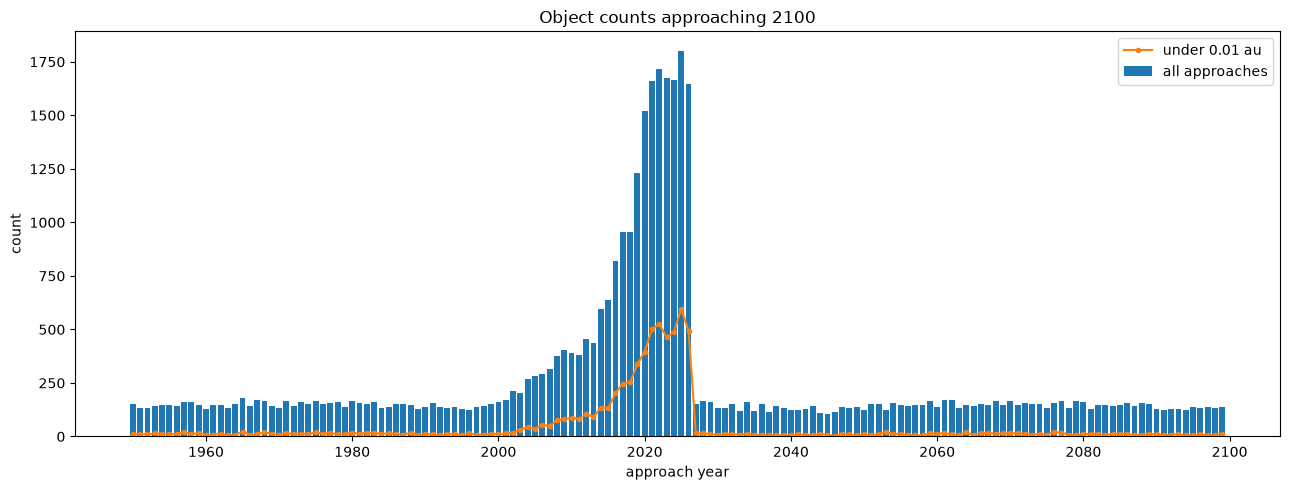

In [17]:
ca = df_close_approach.copy()
ca["approach_date"] = pd.to_datetime(ca["approach_date"], utc=True, errors="coerce")

# A failed parse becomes NaN and groupby drops it without a word.
print("unparsed approach_date:", ca["approach_date"].isna().sum(), "(must be 0)")

ca["year"] = ca["approach_date"].dt.year
print("years covered:", int(ca["year"].min()), "to", int(ca["year"].max()))

yearly = ca.groupby("year").agg(total=("des", "size"),
                                under_001_au=("dist", lambda x: (x < 0.01).sum()))

print("\ntotal approaches:", len(ca))
print("under 0.01 au:   ", int((ca["dist"] < 0.01).sum()))

# The first three CAD fetches ran before dist-max and date-min were locked.
cad = df_source[df_source["collection"] == "cad"][["source_file", "row_count", "params"]]
print("\nCAD fetches:")
print(cad.to_string(index=False))

early = cad.loc[cad["params"].astype(str) == "{}", "source_file"].tolist()
print("\nrows still in close_approach from those unparameterised fetches:",
      int(ca["source_file"].isin(early).sum()))

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(yearly.index, yearly["total"], label="all approaches")
ax.plot(yearly.index, yearly["under_001_au"], color="C1", marker=".", label="under 0.01 au")
ax.set_xlabel("approach year"); ax.set_ylabel("count")
ax.set_title("Object counts approaching 2100")
ax.legend(); plt.tight_layout(); plt.show()

- Coverage thins toward 2100, and that is physical, not a data fault: orbital uncertainty grows with time, so JPL predicts fewer approaches confidently further out. 

#### 10. Observation-gap buckets
- The gap between fetch time and last observation is also the strongest single predictor available to the model, so its distribution has to be understood before it is used as a feature.

In [18]:
latest = df_sentry_risk[df_sentry_risk["fetched"] == df_sentry_risk["fetched"].max()].copy()
latest["gap_days"] = (latest["fetched"] - latest["last_obs_ts"]).dt.total_seconds() / 86400

GAP_BINS   = [0, 30, 365, 1825, 1e9]
GAP_LABELS = ["under 30 d", "30 d - 1 y", "1 - 5 y", "over 5 y"]

latest["gap_bucket"] = pd.cut(latest["gap_days"], bins=GAP_BINS, labels=GAP_LABELS)
print(latest["gap_bucket"].value_counts().reindex(GAP_LABELS))

print(latest.nlargest(5, "gap_days")[["des", "h", "ip", "ps_cum", "last_obs_ts", "n_imp"]])

gap_bucket
under 30 d      30
30 d - 1 y     206
1 - 5 y        753
over 5 y      1238
Name: count, dtype: int64
            des      h            ip  ps_cum               last_obs_ts  n_imp
51274   1979 XB  18.54  8.515158e-07   -2.69 1979-12-15 00:00:00+00:00      4
52586   1991 BA  28.79  4.183031e-06   -6.67 1991-01-18 00:00:00+00:00     43
51759  1993 HP1  26.96  5.586000e-08   -8.40 1993-04-27 00:00:00+00:00      2
52194  1993 KA2  29.00  4.177000e-08   -8.83 1993-05-22 00:00:00+00:00      1
51318   1993 UA  25.44  8.455330e-07   -6.60 1993-10-24 00:00:00+00:00      3


- The majority of objects on the risk list have not been observed for years, and only a small handful were seen in the last month.
- This fact explains why an object stays on the list until fresh observations rule an impact out, and most of them are not being observed. The list records ignorance than ranking danger.
- The oldest entries are mostly small objects seen once, decades ago, and never again. The exception at the top is large, and it ranks high on the Palermo scale for that reason rather than because an impact is expected. Size and uncertainty together produce hazard.

#### 11. Does ip rank the same objects as ps_cum?
- Both columns rank risk, and if they disagree the choice between them is a design decision that has to be made deliberately.

overlap: 3 of 20

TOP BY ip
        des       ip  ps_cum  ps_max     h  n_imp  range_start
 2010 RF12 0.102637   -2.96   -2.96 28.39     70         2095
  2020 CD3 0.025234   -5.17   -5.63 31.75    115         2082
2026 TQ128 0.017224   -5.37   -5.89 31.70    473         2078
 2017 WT28 0.011544   -3.83   -3.85 28.08    113         2083
2006 RH120 0.008167   -4.29   -4.45 29.64    119         2044
   2020 VW 0.007026   -3.81   -4.10 28.32     12         2074
  2026 CQ4 0.005030   -3.72   -3.80 27.57     39         2072
 2006 JY26 0.005001   -4.14   -4.15 28.35    123         2073
  2020 CQ1 0.004646   -4.32   -4.33 28.81     50         2070
 2022 SX55 0.004020   -4.17   -4.17 30.26      7         2035
  2022 NX1 0.003172   -4.23   -4.28 28.03     50         2075
2000 SG344 0.002743   -2.76   -3.10 24.79    300         2069
  2012 HG2 0.002684   -3.70   -4.07 26.97    821         2052
   2017 LD 0.002526   -4.09   -4.68 27.53    418         2053
 2025 FK14 0.002491   -4.98   -4.99 29.65

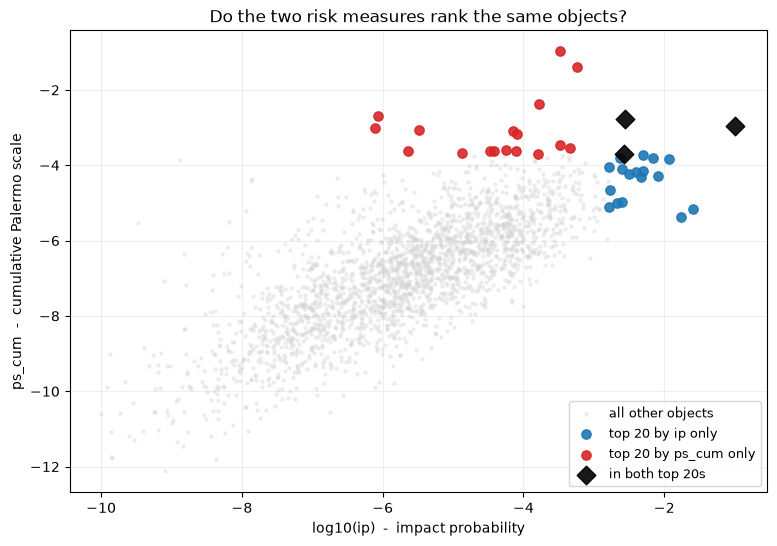

In [19]:
cols = ["des", "ip", "ps_cum", "ps_max", "h", "n_imp", "range_start"]
by_ip = latest.nlargest(20, "ip")
by_ps = latest.nlargest(20, "ps_cum")

set_ip = set(by_ip["des"])
set_ps = set(by_ps["des"])
both   = set_ip & set_ps

print("overlap:", len(both), "of 20\n")
print("TOP BY ip\n",     by_ip[cols].to_string(index=False))
print("\nTOP BY ps_cum\n", by_ps[cols].to_string(index=False))

# log10 silently drops nulls and zeros from the plot, so count them first
print("\nip null or <= 0:", int((latest["ip"].isna() | (latest["ip"] <= 0)).sum()))

is_both = latest["des"].isin(both)
is_ip   = latest["des"].isin(set_ip - both)
is_ps   = latest["des"].isin(set_ps - both)
is_rest = ~(is_both | is_ip | is_ps)

x = np.log10(latest["ip"])
y = latest["ps_cum"]

plt.figure(figsize=(9, 6))
plt.scatter(x[is_rest], y[is_rest], s=5,  alpha=0.3, color="lightgrey", label="all other objects", zorder=1)
plt.scatter(x[is_ip],   y[is_ip],   s=45, alpha=0.9, color="tab:blue", label="top 20 by ip only", zorder=3)
plt.scatter(x[is_ps],   y[is_ps],   s=45, alpha=0.9, color="tab:red", label="top 20 by ps_cum only", zorder=3)
plt.scatter(x[is_both], y[is_both], s=90, alpha=0.9, color="black", marker="D", label="in both top 20s", zorder=4)

plt.xlabel("log10(ip)  -  impact probability")
plt.ylabel("ps_cum  -  cumulative Palermo scale")
plt.title("Do the two risk measures rank the same objects?")
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.2)
plt.show()

- The two measures rank different objects. The leaders by raw impact probability
  are metre-scale bodies, and their probabilities are high precisely because
  their orbits are poorly determined - the same fact expressed by their large
  number of impact solutions. High probability here means high uncertainty, not
  high danger.
- The Palermo scale folds in impact energy and time to impact, which is why it
  exists. Sorting by raw probability alone would present a harmless few-metre
  rock as the greatest threat to Earth.
- So the endpoint sorts by Palermo by default and exposes probability as an
  option. Both belong in the response, because they answer different questions.

#### 12. Alias coverage
- We need to first know which name forms exist in the alias table and how widely each is populated.
- Checking whether any single name points at more than one object confirms the loader rather than the database.

In [20]:
al = df_object_alias

print(al["alias_type"].value_counts(), "\n")
print("objects in object_dimension:", df_object_dim["spkid"].nunique())
print("\naliases per object:")
print(al.groupby("spkid").size().value_counts().sort_index())

# Does any single name point at two different objects? The PK forbids it,
# so this confirms the loader rather than the database.
collisions = al.groupby("alias_value")["spkid"].nunique()
print("\nalias values pointing at more than one object:", int((collisions > 1).sum()))


def resolve(query):
    """Exact match on any alias. Substring on full_name ONLY when the query
    contains letters - a bare number is a catalogue number, and '433' as a
    substring matches 143381, 144332, 154330 and 27 others."""
    q = query.strip()
    exact = al[al["alias_value"].str.lower() == q.lower()]

    if q.replace(" ", "").isdigit():
        hits = exact
    else:
        like = al[(al["alias_type"] == "full_name")
                  & al["alias_value"].str.contains(q, case=False, regex=False, na=False)]
        hits = pd.concat([exact, like]).drop_duplicates()

    return hits[["alias_type", "alias_value", "spkid"]]


for q in ["99942", "2004 MN4", "Apophis", "bK11T00O", "1979 XB", "433"]:
    hits = resolve(q)
    print(f"\n{q!r}   rows found: {len(hits)}")
    print(hits.head(5).to_string(index=False))

alias_type
pdes         43015
full_name    43015
sentry_id     2224
Name: count, dtype: int64 

objects in object_dimension: 43015

aliases per object:
2    40791
3     2224
Name: count, dtype: int64

alias values pointing at more than one object: 0

'99942'   rows found: 1
alias_type alias_value    spkid
      pdes       99942 20099942

'2004 MN4'   rows found: 1
alias_type              alias_value    spkid
 full_name 99942 Apophis (2004 MN4) 20099942

'Apophis'   rows found: 1
alias_type              alias_value    spkid
 full_name 99942 Apophis (2004 MN4) 20099942

'bK11T00O'   rows found: 1
alias_type alias_value    spkid
 sentry_id    bK11T00O 50580987

'1979 XB'   rows found: 2
alias_type alias_value    spkid
      pdes     1979 XB 50012416
 full_name   (1979 XB) 50012416

'433'   rows found: 1
alias_type alias_value    spkid
      pdes         433 20000433


- The primary designation and full name are present for every object, but the packed Sentry identifier exists only for objects that have appeared on the risk list. So a packed designation that fails to resolve may be genuinely unknown, or may simply belong to an object never considered a risk.
- The former designation and the common name of a renamed object have no alias row of their own - they survive only inside the full-name string. 
- A purely numeric query is a catalogue number, and matching it as a substring returns every object whose own number happens to contain those digits. Numeric queries are matched exactly - only queries containing letters use the substring path.

#### 13. Is the estimated diameter trustworthy?
- Publish an estimated size for nearly every object in the catalogue, derived from brightness using an assumed albedo nobody measured. Impact energy scales with the cube of diameter, so a modest size error becomes a large energy error.
- The objects that do have a measured diameter are the only check available on that assumption.

objects with both h and diameter: 1244
  of those, on the Sentry list:   10
median ratio:      0.975
within factor 2:   82.2 %
measured albedo median (this set): 0.137
albedo that would centre it:       0.133


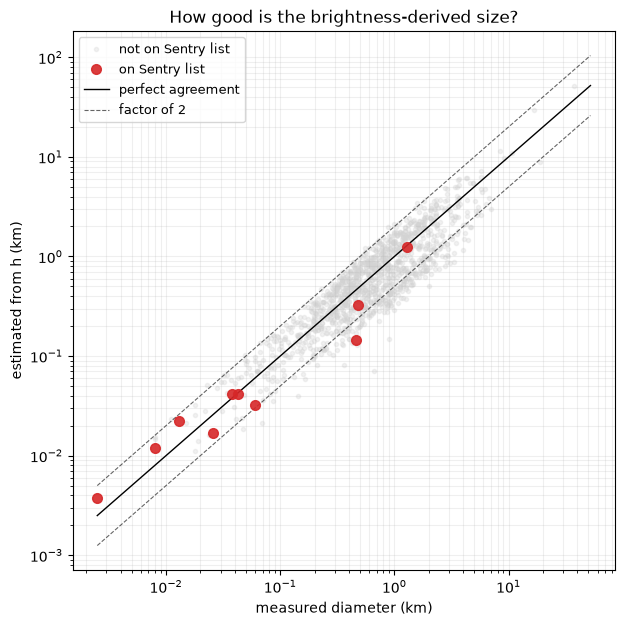

In [21]:
od = df_object_dim
both = od[od["diameter"].notna() & od["h"].notna()].copy()

ALBEDO = 0.14
both["d_est"] = (1329 / np.sqrt(ALBEDO)) * 10 ** (-both["h"] / 5)
both["ratio"] = both["d_est"] / both["diameter"]

# built explicitly rather than assumed to exist from an earlier cell.
# cast to int64: spkid arrives as float64 wherever the column has nulls, and a
# set of floats will not match an int64 column reliably.
sentry_spkids = set(df_sentry_risk["spkid"].dropna().astype("int64"))
both["on_sentry"] = both["spkid"].isin(sentry_spkids)

print("objects with both h and diameter:", len(both))
print("  of those, on the Sentry list:  ", int(both["on_sentry"].sum()))
print("median ratio:     ", round(both["ratio"].median(), 3))
print("within factor 2:  ", round(both["ratio"].between(0.5, 2).mean() * 100, 1), "%")

# the albedo of THESE objects, not of the whole catalogue - the comparison is
# only like-for-like against the population the ratio was measured on
print("measured albedo median (this set):", round(both["albedo"].median(), 3))
print("albedo that would centre it:      ",
      round(ALBEDO * both["ratio"].median() ** 2, 3))

is_s = both["on_sentry"]

plt.figure(figsize=(7, 7))
plt.loglog(both.loc[~is_s, "diameter"], both.loc[~is_s, "d_est"], ".", 
           alpha=0.3, color="lightgrey", label="not on Sentry list", zorder=1)
plt.loglog(both.loc[is_s, "diameter"], both.loc[is_s, "d_est"], "o",
           ms=7, alpha=0.9, color="tab:red", label="on Sentry list", zorder=3)

# span both axes so the reference lines cross the whole cloud, even where the
# estimate falls outside the range of measured values
low  = min(both["diameter"].min(), both["d_est"].min())
high = max(both["diameter"].max(), both["d_est"].max())
lims = np.array([low, high])
plt.loglog(lims, lims, "k-",  lw=1, label="perfect agreement", zorder=2)
plt.loglog(lims, lims * 2, "k--", lw=0.8, alpha=0.6, label="factor of 2", zorder=2)
plt.loglog(lims, lims * 0.5, "k--", lw=0.8, alpha=0.6, zorder=2)

plt.xlabel("measured diameter (km)")
plt.ylabel("estimated from h (km)")
plt.title("How good is the brightness-derived size?")
plt.legend(loc="upper left", fontsize=9)
plt.grid(alpha=0.2, which="both")
plt.show()

- What matters is the spread, not the central value.
- The refitted albedo is the actionable output. Because diameter varies as the inverse square root of albedo, scaling the assumed value by the squared median ratio removes the systematic bias - and comparing it to the median measured albedo says whether the original assumption was reasonable.
- The validation set is biased by construction, and the coloring shows it. The objects with a measured diameter are the large, bright, well-observed ones, because that is what radar and thermal measurement require - so the few that are also on the risk list sit at the large end of the cloud, and the small objects that dominate the risk list are absent from the plot entirely. The estimate's accuracy on exactly the objects we care about most is therefore untested.

#### 14. What is the size distribution of the catalogue, and how does the risk list sit inside it?

on_sentry   False  True 
size_bin                
<10 m        1828    909
10-30 m      9674   1027
30-140 m    17265    273
140-300 m    5851     13
300 m-1 km   5075      7
1-3 km        791      1
>3 km          83      0


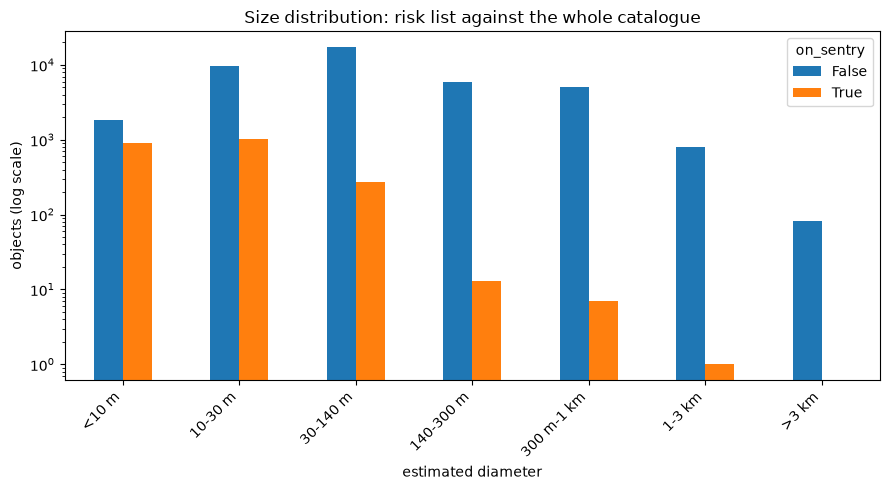

In [22]:
ALBEDO_FIT = 0.14          # replace with the refitted value from section 13
d = df_object_dim.copy()
d["d_est"] = (1329 / np.sqrt(ALBEDO_FIT)) * 10 ** (-d["h"] / 5)
d = d[d["d_est"].notna()]

# the 140 m and 1 km edges are not round numbers chosen for looks: 140 m is the
# survey threshold that defines a potentially hazardous object, and 1 km is the
# size above which an impact has global rather than regional effects.
edges  = [0, 0.01, 0.03, 0.14, 0.3, 1, 3, np.inf]
labels = ["<10 m", "10-30 m", "30-140 m", "140-300 m",
          "300 m-1 km", "1-3 km", ">3 km"]
d["size_bin"] = pd.cut(d["d_est"], bins=edges, labels=labels)

sentry_spkids = set(df_sentry_risk["spkid"].dropna().astype("int64"))
d["on_sentry"] = d["spkid"].isin(sentry_spkids)

table = pd.crosstab(d["size_bin"], d["on_sentry"])
print(table)

table.plot(kind="bar", figsize=(9, 5), logy=True)
plt.ylabel("objects (log scale)")
plt.xlabel("estimated diameter")
plt.title("Size distribution: risk list against the whole catalogue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

- The catalogue falls away steeply with size: there are far more small objects than large ones, by a wide margin at every step up in diameter. This is the expected signature of a population produced by collisions, where each break-up yields many fragments and few large survivors.
- The risk list sits toward the small end relative to the catalogue as a whole. Sentry selects for objects whose orbits are poorly determined, and small objects are poorly determined because they are faint and seldom observed.
- Small objects enter the catalogue only when they happen to pass close enough to be detected, so their counts measure our detection limit, not how many exist. 

#### 15. How many orbit solutions does a single object accumulate?
- How many orbit solutions does one object accumulate? 
- Does an object on the risk list get refitted more often than an average object? The model assumes it does - orbit_age_days is only predictive if refit rate varies between objects.

In [23]:
per_object = df_orbit.groupby("spkid").size()
print(per_object.describe())
print("\nobjects with more than one solution:", int((per_object > 1).sum()))
print("deepest history:", int(per_object.max()))

count    43015.000000
mean         1.034779
std          0.287928
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          5.000000
dtype: float64

objects with more than one solution: 820
deepest history: 5


In [24]:
per_object = df_orbit.groupby("spkid").size()

sentry_spkids = set(df_sentry_risk["spkid"].dropna().astype("int64"))
on_s = per_object.index.isin(sentry_spkids)

print("share with >1 solution, on Sentry:    ",
      round((per_object[on_s] > 1).mean() * 100, 2), "%")
print("share with >1 solution, not on Sentry:",
      round((per_object[~on_s] > 1).mean() * 100, 2), "%")
print("mean solutions, on Sentry:    ", round(per_object[on_s].mean(), 3))
print("mean solutions, not on Sentry:", round(per_object[~on_s].mean(), 3))

# the ceiling on this whole measurement: an object cannot have more solutions
# than there have been SBDB fetches to observe them in.
print("\nSBDB fetches so far:",
      int((df_source["collection"] == "sbdb").sum()))

share with >1 solution, on Sentry:     1.12 %
share with >1 solution, not on Sentry: 1.95 %
mean solutions, on Sentry:     1.02
mean solutions, not on Sentry: 1.036

SBDB fetches so far: 7


- Almost every object carries a single orbit solution, and the deepest history in the catalogue is only a few rows deep. An object cannot show more solutions than there have been snapshots to observe them in, and the deepest history found is close to the number of fetches performed, so the measurement is bounded by our own history rather than by JPL's refit behaviour.
- Majority of objects have exactly one solution dating from the pipeline's first snapshot, orbit age reduces for most rows to time elapsed since the pipeline started - a pure function of the snapshot timestamp. It distinguishes no object from another, and under a time-based split every training value is lower than every test value, so any split learned on it is guaranteed not to generalise.
- The objects that do hold several solutions confirm the slowly-changing dimension is appending history rather than overwriting in place. Had every object come back with exactly one, the temporal join in the training query would have been meaningless - matching the only row that exists, whatever date was asked for.